# Entropy in Quantitative Finance: A Comprehensive Guide

Entropy is a foundational concept from Information Theory (developed by Claude Shannon in 1948) that measures the amount of **uncertainty, randomness, or "surprise"** in a system. In quantitative finance, we use entropy to measure the predictability of asset prices, discover market regimes, and identify statistically significant relationships between variables.

This notebook provides an in-depth exploration of various entropy types, including:
1. **Marginal Shannon Entropy**
2. **Rolling Shannon Entropy (Regime Detection)**
3. **Directional Entropy (Markov Chains)**
4. **Mutual Information (Dependence)**
5. **Approximate Entropy (ApEn)**

For each concept, we structured the breakdown into:
- **What is it?** Let's define it simply.
- **Why do we care?** Practical applications in trading.
- **The Formula:** The mathematical underpinning.
- **How is it implemented?** Python code examples with 2D and 3D visualizations.


In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from sklearn.metrics import mutual_info_score
from scipy.stats import entropy
import warnings
warnings.filterwarnings('ignore')

plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = (14, 7)

# Download Sample Data: Bitcoin (BTC-USD) provides a good example of shifting regimes
ticker = 'BTC-USD'
data = yf.download(ticker, start='2018-01-01', end='2026-01-01')
data['Log_Return'] = np.log(data['Close'] / data['Close'].shift(1))
data.dropna(inplace=True)


c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
[*********************100%***********************]  1 of 1 completed


## 1. Marginal Shannon Entropy

### What is it?
Shannon Entropy quantifies the expected value of the information contained in a message (or a time series of returns). In trading terms, it measures how spread out the distribution of returns is. If an asset always returns 0.1% a day, its entropy is 0 (perfectly predictable). If it can return any value with equal probability, its entropy is maximized.

### Why do we care?
While standard deviation (volatility) measures the magnitude of price swings in assumed normal distributions, **Shannon Entropy measures the true randomness of the distribution**, without assuming normality. Higher entropy means lower predictability. Lower entropy means the market is exhibiting a structure (either trending or mean-reverting), suggesting an exploitable anomaly.

### The Formula
For a discrete random variable $X$ with possible outcomes $x_i$ and probabilities $P(x_i)$:
$$ H(X) = - \sum_{i} P(x_i) \log_2 P(x_i) $$

Since asset returns are continuous, we must discretize (bin) them into finite intervals to compute probabilities.

### How is it implemented?
We use histogram binning to calculate the probability of a return falling into a particular bin, then calculate entropy in bits.


In [2]:
def calculate_shannon_entropy(series, bins=50):
    """
    Calculates the Shannon Entropy of a return series.
    """
    # Discretize the series into bins
    hist, bin_edges = np.histogram(series, bins=bins, density=False)
    
    # Calculate probabilities
    probs = hist / np.sum(hist)
    
    # Remove zero probabilities to avoid log(0)
    probs = probs[probs > 0]
    
    # Calculate Shannon Entropy in bits (log base 2)
    shannon_ent = -np.sum(probs * np.log2(probs))
    
    return shannon_ent

overall_entropy = calculate_shannon_entropy(data['Log_Return'])
print(f"Overall Shannon Entropy for {ticker}: {overall_entropy:.4f} bits")


Overall Shannon Entropy for BTC-USD: 3.2636 bits


## 2. Rolling Shannon Entropy (Regime Detection)

### What is it?
Markets are not static. Rolling Shannon Entropy applies the entropy calculation over a moving window of time.

### Why do we care?
Rolling entropy acts as an excellent **Regime Filter**.
- **High Rolling Entropy**: The market is random, noisy, and unpredictable. Trend-following and mean-reversion models will likely fail. You should reduce position size or switch off trading.
- **Low Rolling Entropy**: The market is exhibiting structure, momentum, or predictable mean-reversion. A highly favorable regime for algorithmic models.

### The Formula
This uses the exact same formula as Marginal Shannon Entropy, but calculated iteratively over a window $t - w$ to $t$.

### How is it implemented?


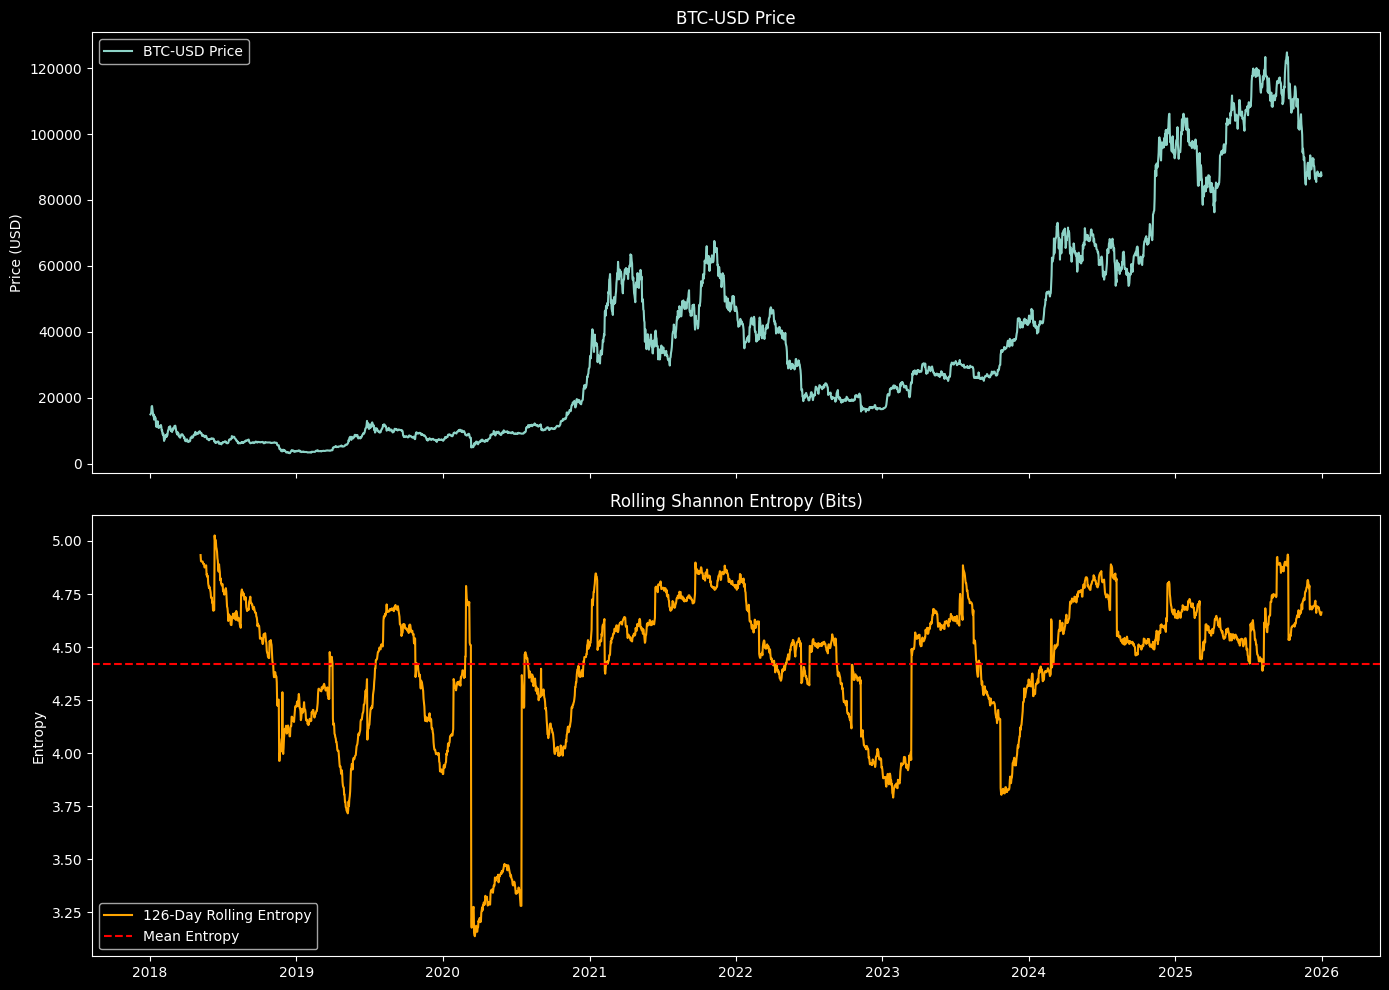

In [3]:
def rolling_shannon_entropy(series, window=252, bins=50):
    """
    Calculates the rolling Shannon Entropy over a specified window.
    """
    rolling_ent = series.rolling(window=window).apply(
        lambda x: calculate_shannon_entropy(x, bins=bins)
    )
    return rolling_ent

data['Rolling_Entropy_126'] = rolling_shannon_entropy(data['Log_Return'], window=126, bins=50)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax1.plot(data.index, data['Close'], label=f'{ticker} Price')
ax1.set_title(f'{ticker} Price')
ax1.set_ylabel('Price (USD)')
ax1.legend()

ax2.plot(data.index, data['Rolling_Entropy_126'], color='orange', label='126-Day Rolling Entropy')
ax2.axhline(data['Rolling_Entropy_126'].mean(), color='red', linestyle='--', label='Mean Entropy')
ax2.set_title('Rolling Shannon Entropy (Bits)')
ax2.set_ylabel('Entropy')
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Directional Entropy (Markov Chains)

### What is it?
Marginal and Rolling Shannon entropy treat order as irrelevant. [0.01, -0.01, 0.01, -0.01] has the same entropy as [0.01, 0.01, -0.01, -0.01]. Directional Entropy looks at the **transition probabilities** between states (e.g., UP vs DOWN).

### Why do we care?
It measures conditional predictability. If the market goes up today, what is the probability it goes up tomorrow? By mapping sequences of up/down days (e.g., UP-UP, UP-DOWN, DOWN-UP, DOWN-DOWN), we can see if there is momentum (continuation) or mean-reversion (alternation) at a microscopic level. 

### The Formula
We define states (e.g., $S_t \in \{Up, Down\}$) and calculate joint probabilities of sequences (words) of length $k$, $P(s_1, s_2, ..., s_k)$.
For pairs ($k=2$):
$$ H(Y|X) = -\sum_{x,y} P(x,y) \log_2 \left( \frac{P(x,y)}{P(x)} \right) $$

### How is it implemented?
We classify days into UP (1) and DOWN (0) states, create bigrams (pairs of consecutive days), and calculate the entropy of these sequences. We'll also visualize the transition matrix in 2D and 3D.


Overall Directional Entropy for BTC-USD: 1.9966 bits


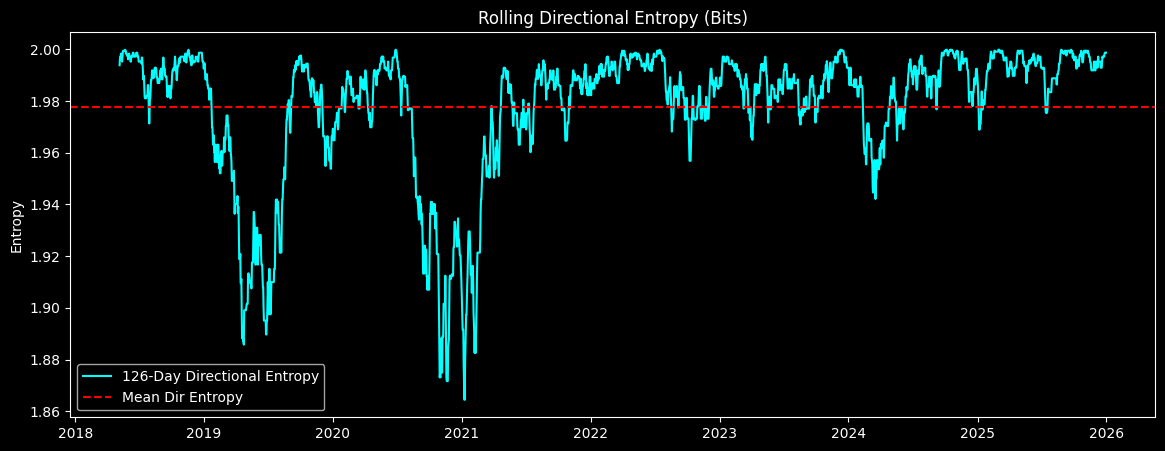

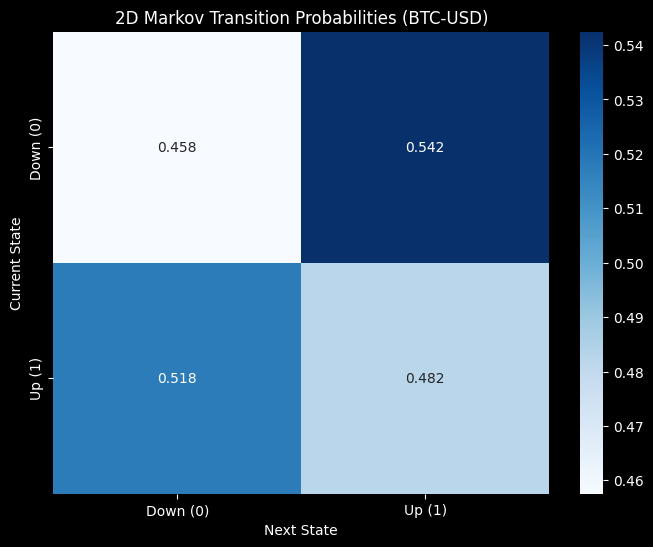

In [4]:
def calculate_directional_entropy(series):
    """
    Calculates directional entropy by looking at UP/DOWN transitions.
    """
    # 1. Convert to states (1 for Up, 0 for Down)
    states = (series > 0).astype(int).values
    
    # 2. Create overlapping pairs (transition sequences)
    pairs = [str(states[i]) + str(states[i+1]) for i in range(len(states)-1)]
    
    # 3. Calculate frequencies of each pair (00, 01, 10, 11)
    pair_counts = pd.Series(pairs).value_counts()
    probs = pair_counts.values / np.sum(pair_counts.values)
    
    # 4. Calculate entropy
    dir_ent = -np.sum(probs * np.log2(probs))
    
    return dir_ent

overall_dir_ent = calculate_directional_entropy(data['Log_Return'])
print(f"Overall Directional Entropy for {ticker}: {overall_dir_ent:.4f} bits")

def rolling_directional_entropy(series, window=126):
    rolling_dir_ent = series.rolling(window=window).apply(calculate_directional_entropy)
    return rolling_dir_ent

data['Rolling_Dir_Entropy_126'] = rolling_directional_entropy(data['Log_Return'], window=126)

# Plotting Directional Entropy
plt.figure(figsize=(14, 5))
plt.plot(data.index, data['Rolling_Dir_Entropy_126'], color='cyan', label='126-Day Directional Entropy')
plt.axhline(data['Rolling_Dir_Entropy_126'].mean(), color='red', linestyle='--', label='Mean Dir Entropy')
plt.title('Rolling Directional Entropy (Bits)')
plt.ylabel('Entropy')
plt.legend()
plt.show()

# Visualize Transition Matrix
# 1. Convert to states
states = (data['Log_Return'] > 0).astype(int).values
pairs = [(states[i], states[i+1]) for i in range(len(states)-1)]

# Create transition matrix
transition_counts = np.zeros((2, 2))
for pair in pairs:
    transition_counts[pair[0], pair[1]] += 1

# Normalize to probabilities
transition_probs = transition_counts / transition_counts.sum(axis=1)[:, None]

# 2D Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(transition_probs, annot=True, cmap='Blues', fmt='.3f',
            xticklabels=['Down (0)', 'Up (1)'],
            yticklabels=['Down (0)', 'Up (1)'])
plt.title('2D Markov Transition Probabilities (BTC-USD)')
plt.ylabel('Current State')
plt.xlabel('Next State')
plt.show()

# 3D Plotly Surface
fig = go.Figure(data=[go.Surface(z=transition_probs, x=['Down', 'Up'], y=['Down', 'Up'], colorscale='Viridis')])
fig.update_layout(title='3D Markov Transition Surface',
                  scene=dict(
                      xaxis_title='Next State',
                      yaxis_title='Current State',
                      zaxis_title='Probability',
                  ),
                  width=800, height=600)
fig.show()


### How to Read the 3D Markov Transition Surface

This 3D surface plot visualizes the **transitional probabilities** between different market states (e.g., Down days vs. Up days). Here is how to interpret the visual:

- **X and Y Axes (Current State & Next State):** These represent the defined market states. The surface maps all possible transitions from what the market is doing *now* (Current State) to what it might do *next* (Next State).
- **Z-Axis (Probability):** The height of the surface represents the probability of that specific transition occurring. Higher points indicate a more likely transition.
- **Color Gradient:** The color scale directly maps to the probability (Z-axis). Based on the legend, warmer colors (yellow/green) indicate higher probabilities, while cooler colors (dark blue/purple) indicate lower probabilities.

**Why does this matter?**
If the asset followed a perfectly random walk, the surface would be completely flat at 0.5 (a 50% chance of going Up or Down regardless of the current state). 

The saddle-like "warped" shape we see here reveals that the market exhibits **non-random structure (lower directional entropy)**. The varying probabilities mean that the market has a statistical memory—certain states are more likely to follow others. This structural imbalance is exactly what quantitative models (like mean-reversion or momentum) seek to exploit!

## 4. Mutual Information (Non-Linear Dependence)

### What is it?
Mutual Information (MI) measures the mutual dependence between two distinct variables. It quantifies the "amount of information" obtained about one random variable through observing the other random variable.

### Why do we care?
Correlation ($r$) only measures linear dependence. Standard pairs trading using correlation breaks down in non-linear regimes. **Mutual information detects ANY dependence (linear or non-linear)**. This is immensely powerful for statistical arbitrage, copula modeling, and feature selection in machine learning, where asset pairs might have a complex relationship missed by standard correlation.

### The Formula
$$ I(X;Y) = \sum_{y \in Y} \sum_{x \in X} P(x,y) \log \left( \frac{P(x,y)}{P(x)P(y)} \right) $$
Alternatively: $I(X;Y) = H(X) + H(Y) - H(X,Y)$

### How is it implemented?
We use `sklearn.metrics.mutual_info_score` on binned returns of two assets.


In [5]:
# Let's download a second asset to compute MI
asset2_ticker = '^GSPC' # S&P 500
data2 = yf.download(asset2_ticker, start='2018-01-01', end='2026-01-01')
data2['Log_Return'] = np.log(data2['Close'] / data2['Close'].shift(1))
data['SPY_Return'] = data2['Log_Return']
data.dropna(inplace=True)

def calculate_mutual_information(series1, series2, bins=50):
    """
    Calculates the mutual information between two series.
    """
    # We must discretize for MI
    c_xy = np.histogram2d(series1, series2, bins)[0]
    return mutual_info_score(None, None, contingency=c_xy)

mi = calculate_mutual_information(data['Log_Return'], data['SPY_Return'])
corr = data['Log_Return'].corr(data['SPY_Return'])

print(f"Pearson Correlation between {ticker} and S&P 500: {corr:.4f}")
print(f"Mutual Information between {ticker} and S&P 500: {mi:.4f} nats")


[*********************100%***********************]  1 of 1 completed

Pearson Correlation between BTC-USD and S&P 500: 0.3252
Mutual Information between BTC-USD and S&P 500: 0.1536 nats


## 5. Approximate Entropy (ApEn)

### What is it?
Approximate Entropy (ApEn) is a technique used to quantify the amount of regularity and the unpredictability of fluctuations over time-series data. Unlike Shannon Entropy which requires discretizing the data, ApEn works directly on continuous time-series data.

### Why do we care?
ApEn is heavily used for physical systems and biological signals (like heart rates), but it's highly potent for financial time series. It asks: "If two sequences of length $m$ are similar within a tolerance $r$, what is the probability that the sequences of length $m+1$ will also be similar?"
A low ApEn value indicates high persistence and periodicity (a highly predictable trend). A high ApEn value indicates low persistence (random walk/noise).

### The Formula
1. Form sequences of length $m$: $X_i = [x_i, x_{i+1}, ..., x_{i+m-1}]$
2. For each sequence, count how many other sequences are within distance $r$ (usually $r = 0.2 \times \sigma$). This gives $C_i^m(r)$.
3. Compute the log average: $\Phi^m(r) = \frac{1}{N-m+1} \sum \ln C_i^m(r)$
4. Repeat for length $m+1$ to find $\Phi^{m+1}(r)$.
5. $ApEn(m, r) = \Phi^m(r) - \Phi^{m+1}(r)$

### How is it implemented?
Calculating ApEn computationally can be expensive. We provide an optimized vectorized version.


In [6]:
def approximate_entropy(U, m=2, r=None):
    """
    Computes Approximate Entropy (ApEn) of a time series.
    m: length of compared run of data (typically 2)
    r: filtering level, typically 0.2 * std of data
    """
    U = np.array(U)
    N = len(U)
    if r is None:
        r = 0.2 * np.std(U)

    def _maxdist(x_i, x_j):
        return np.max(np.abs(x_i - x_j))

    def _phi(m):
        x = np.array([U[i:i+m] for i in range(N - m + 1)])
        # C tracks how many vectors are within distance r
        C = np.zeros(len(x))
        for i in range(len(x)):
            # Distance calculated as maximum absolute difference between scalar components
            distances = np.max(np.abs(np.tile(x[i], (len(x), 1)) - x), axis=1)
            C[i] = np.sum(distances <= r) / (N - m + 1)
        return np.sum(np.log(C)) / (N - m + 1)

    return _phi(m) - _phi(m + 1)

# Calculate over a small sample to avoid extremely long computation times
sample_data = data['Log_Return'].values[-500:] # Last 500 days
apen_val = approximate_entropy(sample_data, m=2)
print(f"Approximate Entropy ({ticker}, last 500D): {apen_val:.4f}")


Approximate Entropy (BTC-USD, last 500D): 1.3381
